# ITVItae - Deep Learning and SHAP Exam

1. Train a CNN on the fashion mnist dataset (25%). ✔
2. Compute the Shapley values for examples of each class (25%). ✔
3. Visualize these values (25%). ✔
4. How can the model distinguish between a t-shirt and a pullover? (25%). ✔



Use the following code to load, reshape and normalize the fashion mnist dataset:
```
# class label list
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Download the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Reshape and normalize data
x_train = x_train.reshape(60000, 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(10000, 28, 28, 1).astype("float32") / 255
```

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import shap
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

seed = 7

In [12]:

# class label list
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Download the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Reshape and normalize data
x_train = x_train.reshape(60000, 28, 28, 1).astype("float32") / 255
x_test = x_test.reshape(10000, 28, 28, 1).astype("float32") / 255


In [13]:
# Model / data parameters
num_classes = 10
input_shape = (28, 28, 1)

# the data, split between train and test sets
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

# Scale images to the [0, 1] range
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

x_train shape: (60000, 28, 28, 1)
60000 train samples
10000 test samples


In [14]:
num_classes = 10
input_shape = (28, 28, 1)

model = keras.Sequential(
    [
        keras.Input(shape=input_shape),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation="softmax"),
    ]
)

#model.summary()

In [15]:
batch_size = 128
epochs = 3

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/3


2026-05-07 14:27:49.200114: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 169344000 exceeds 10% of free system memory.


422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.6488 - loss: 1.0050 - val_accuracy: 0.8415 - val_loss: 0.4460
Epoch 2/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 11s 26ms/step - accuracy: 0.8336 - loss: 0.4588 - val_accuracy: 0.8637 - val_loss: 0.3753
Epoch 3/3
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.8563 - loss: 0.4007 - val_accuracy: 0.8700 - val_loss: 0.3557


In [16]:
score = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", score[0])
print("Test accuracy:", score[1])

Test loss: 0.37486883997917175
Test accuracy: 0.8658000230789185


In [17]:
images_dict = dict()
for i, l in enumerate(y_train.argmax(axis = 1)):
  if len(images_dict)==10:
    break
  if l not in images_dict.keys():
    images_dict[l] = x_train[i].reshape((28, 28))


In [18]:
x_test_dict = dict()
for i, l in enumerate(y_test.argmax(axis = 1)):
  if len(x_test_dict)==10:
    break
  if l not in x_test_dict.keys():
    x_test_dict[l] = x_test[i]

# Convert to list preserving order of classes
x_test_each_class = [x_test_dict[i] for i in sorted(x_test_dict)]

# Convert to tensor
x_test_each_class = np.asarray(x_test_each_class)
    
# Predictions 
predictions = model.predict(x_test_each_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


2. Compute the Shapley values for examples of each class (25%).
3. Visualize these values (25%).
4. How can the model distinguish between a t-shirt and a pullover? (25%).

In [19]:
# select a set of background examples to take an expectation over
background = x_train[np.random.choice(x_train.shape[0], 100, replace=False)]

# explain predictions of the model on an example of each class
e = shap.DeepExplainer(model, background)
shap_values = e.shap_values(x_test_each_class)

/home/ngard/anaconda3/envs/Assignment/lib/python3.9/site-packages/shap/explainers/_deep/deep_tf.py:94: UserWarning: Your TensorFlow version is newer than 2.4.0 and so graph support has been removed in eager mode and some static graphs may not be supported. See PR #1483 for discussion.
  warnings.warn(
/home/ngard/anaconda3/envs/Assignment/lib/python3.9/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_8
Received: inputs=['Tensor(shape=(100, 28, 28, 1))']
  warnings.warn(msg)
/home/ngard/anaconda3/envs/Assignment/lib/python3.9/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_8
Received: inputs=['Tensor(shape=(200, 28, 28, 1))']
  warnings.warn(msg)
/home/ngard/anaconda3/envs/Assignment/lib/python3.9/site-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` do

In [20]:
# Function to plot images
def plot_categories(images, class_names):
  fig, axes = plt.subplots(1, 11, figsize=(16, 15))
  axes = axes.flatten()
  
  # Plot an empty canvas
  ax = axes[0]
  dummy_array = np.array([[[0, 0, 0, 0]]], dtype='uint8')
  ax.set_title("reference")
  ax.set_axis_off()
  ax.imshow(dummy_array, interpolation='nearest')

  # Plot an image for every category
  for k,v in images.items():
    ax = axes[k+1]
    ax.imshow(v, cmap=plt.cm.binary)
    ax.set_title(f"{class_names[k]}")
    ax.set_axis_off()

  plt.tight_layout()
  plt.show()

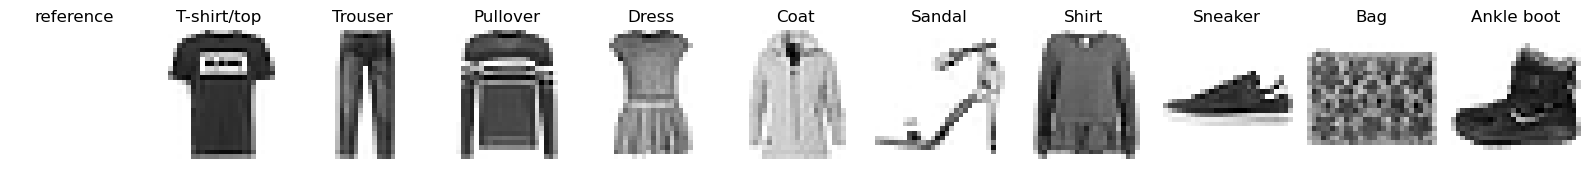

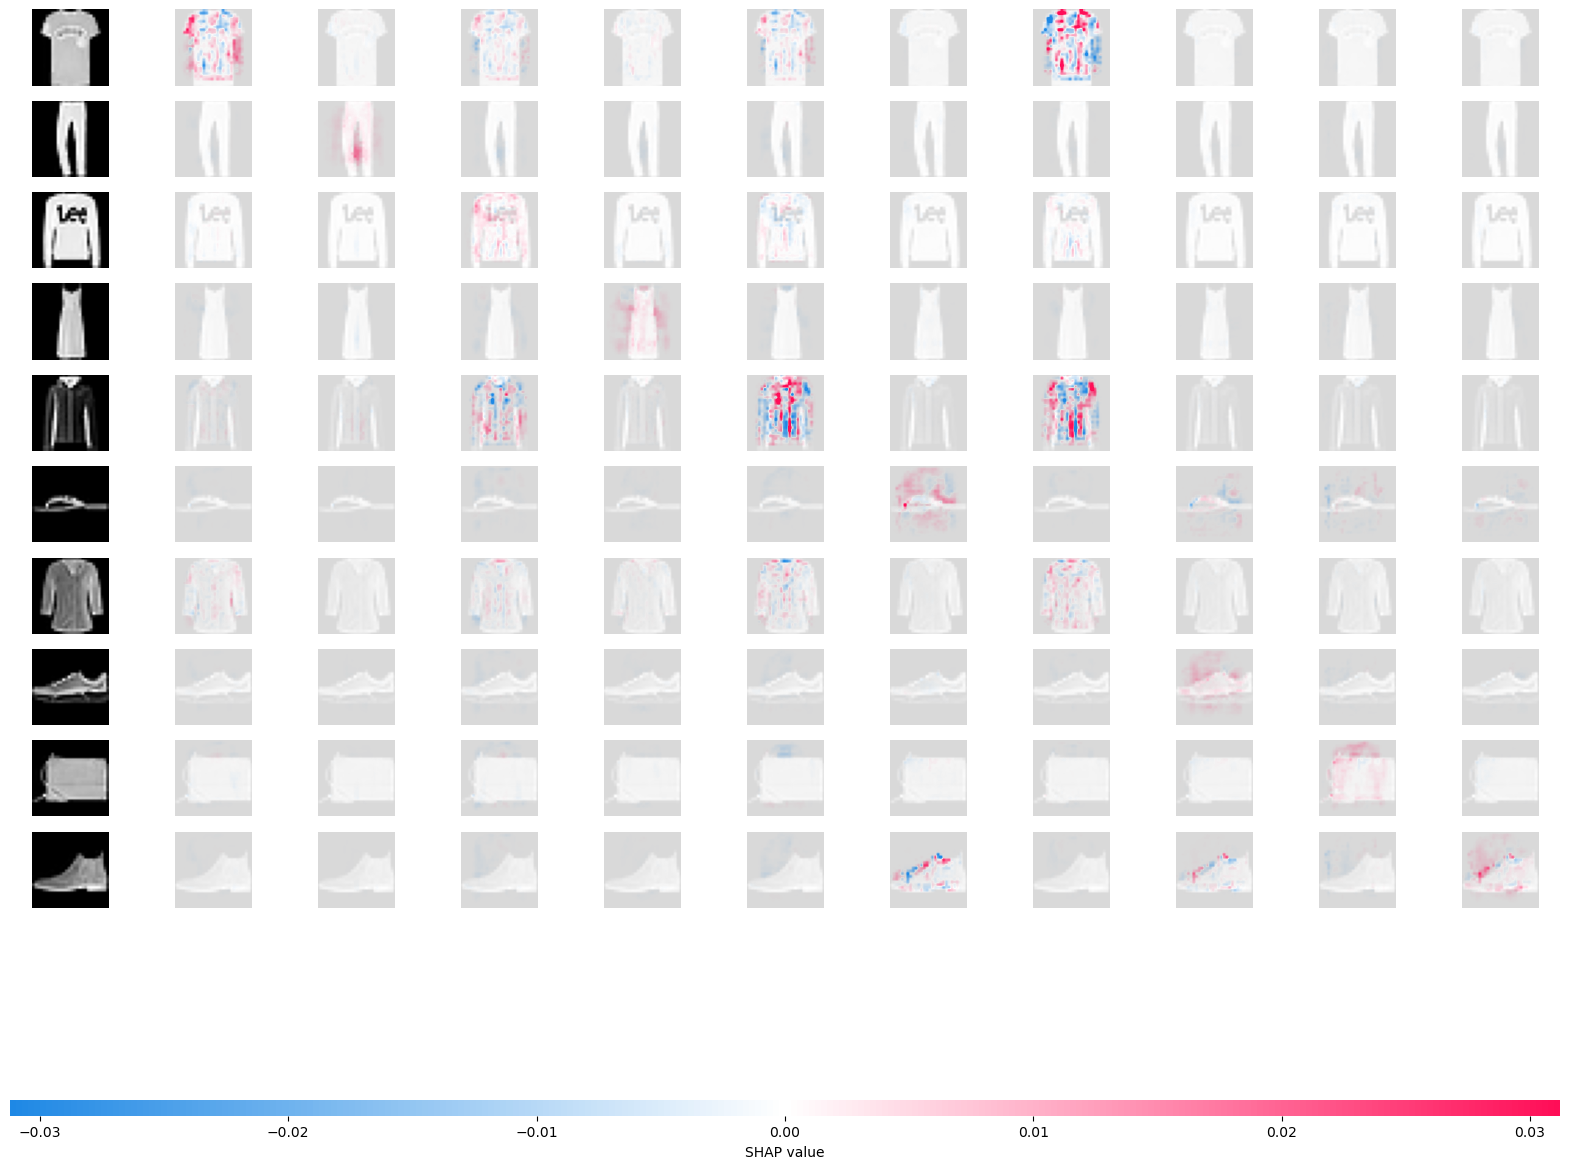

In [21]:
# plot SHAP values
# class label list
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


# plot SHAP values
# class label list
plot_categories(images_dict, class_names)
# Print an empty line to separate the two plots
print()
# Plot shap values
shap_numpy = list(np.transpose(shap_values, (4, 0, 1, 2, 3)))
shap.image_plot(shap_numpy, x_test_each_class)

4. How can the model distinguish between a t-shirt and a pullover?

Tshirt (0) and pullover (2)

1) Looks like the tshirt identify itself by being smaller at the torso and having smaller sleeves.
2) and the pullover identify itself mostly by very long sleeves until the wrist, and its higher and wider at the neck area.